# Pharos 01 - Data exploration

Source: daily point of sale counts for eight ATC drug groups, 2014 to 2019 (2106 days, no gaps). This notebook profiles the series that every model downstream is built on.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.3,'font.size':10})

CATS = ['M01AB','M01AE','N02BA','N02BE','N05B','N05C','R03','R06']
df = pd.read_csv('../data/salesdaily.csv')
df['datum'] = pd.to_datetime(df['datum'], format='%m/%d/%Y')
df = df.set_index('datum').sort_index()[CATS].astype(float)
print(df.shape, df.index.min().date(), '->', df.index.max().date())
df.head()

(2106, 8) 2014-01-02 -> 2019-10-08


,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
datum,,,,,,,,
2014-01-02,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0
2014-01-03,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0
2014-01-04,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0
2014-01-05,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0
2014-01-06,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0


### Completeness and distribution

In [2]:
full = pd.date_range(df.index.min(), df.index.max(), freq='D')
print('missing days:', len(full) - len(df))
df.describe().round(2)

missing days: 0


,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
count,2106.00,2106.00,2106.00,2106.00,2106.00,2106.00,2106.00,2106.00
mean,5.03,3.90,3.88,29.92,8.85,0.59,5.51,2.90
std,2.74,2.13,2.38,15.59,5.61,1.09,6.43,2.42
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,3.00,2.34,2.00,19.00,5.00,0.00,1.00,1.00
50%,4.99,3.67,3.50,26.90,8.00,0.00,4.00,2.00
75%,6.67,5.14,5.20,38.30,12.00,1.00,8.00,4.00
max,17.34,14.46,16.00,161.00,54.83,9.00,45.00,15.00


Demand is dominated by **N02BE** (paracetamol and other anilide analgesics), roughly half of all units. The psycholeptic groups **N05C** and **N05B** are the smallest.

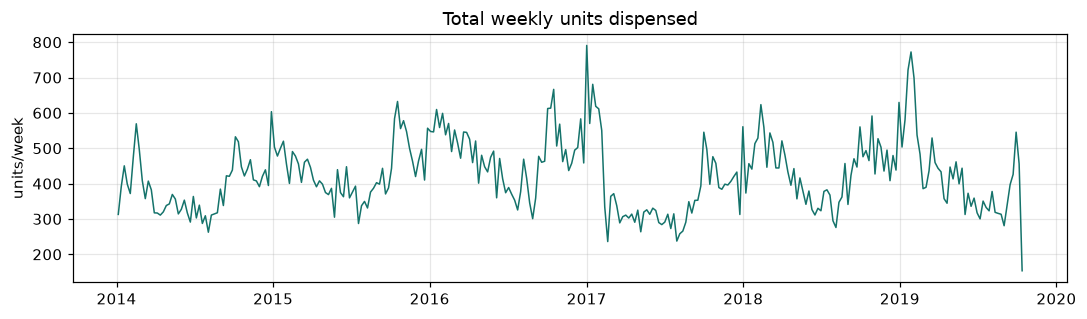

In [3]:
weekly = df.sum(axis=1).resample('W').sum()
fig, ax = plt.subplots(figsize=(10,3))
ax.plot(weekly.index, weekly.values, color='#15736b', lw=1)
ax.set_title('Total weekly units dispensed'); ax.set_ylabel('units/week'); plt.tight_layout()

### Seasonality by group
Monthly averages reveal the clinical seasonality: airway drugs (R03) and antihistamines (R06) swing hardest.

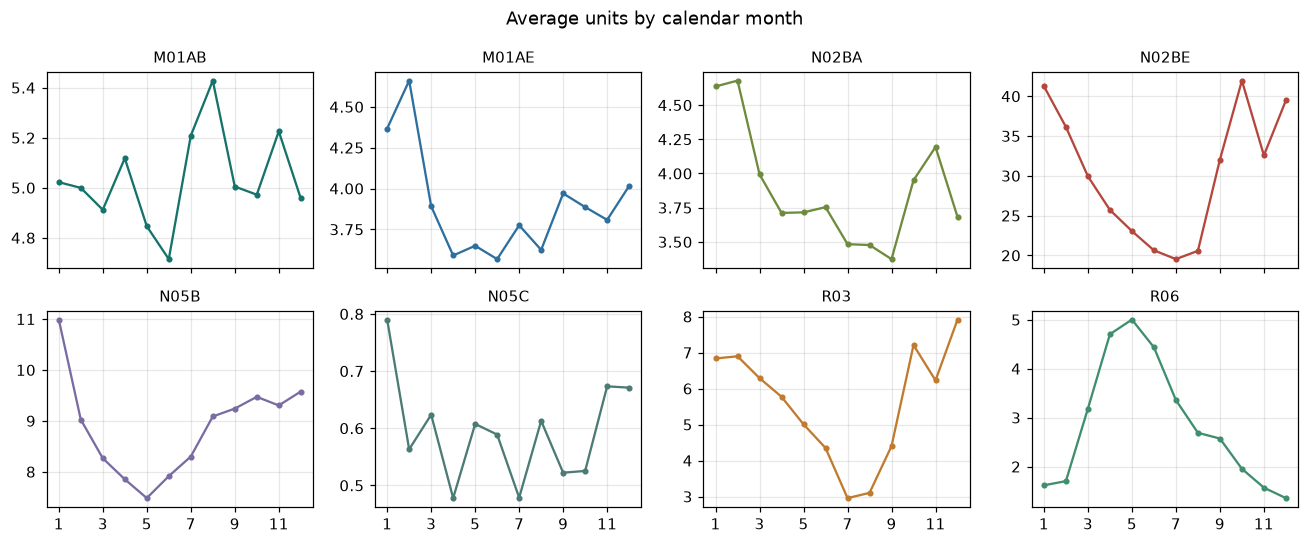

In [4]:
monthly = df.groupby(df.index.month).mean()
fig, axes = plt.subplots(2,4, figsize=(12,5), sharex=True)
colors = dict(zip(CATS, ['#15736b','#2e6f9e','#6e8b3d','#b4463c','#7a6ca3','#4c7a74','#c07b2e','#3f8e6e']))
for ax, c in zip(axes.ravel(), CATS):
    ax.plot(monthly.index, monthly[c], color=colors[c], marker='o', ms=3)
    ax.set_title(c, fontsize=10); ax.set_xticks(range(1,13,2))
fig.suptitle('Average units by calendar month'); plt.tight_layout()

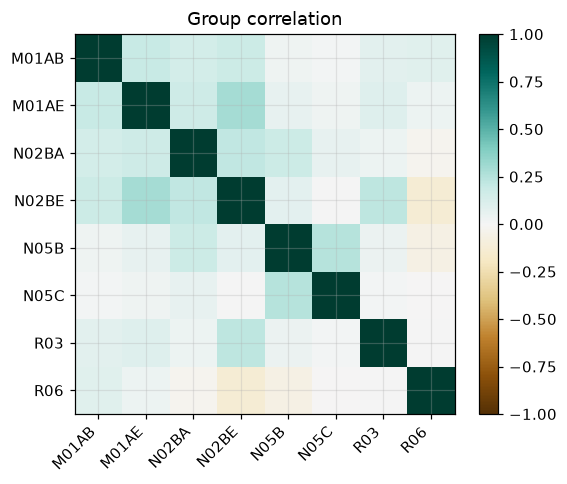

In [5]:
fig, ax = plt.subplots(figsize=(5.5,4.5))
im = ax.imshow(df.corr(), cmap='BrBG', vmin=-1, vmax=1)
ax.set_xticks(range(8)); ax.set_xticklabels(CATS, rotation=45, ha='right')
ax.set_yticks(range(8)); ax.set_yticklabels(CATS)
fig.colorbar(im, fraction=.046); ax.set_title('Group correlation'); plt.tight_layout()

**Takeaways.** The series is clean and continuous, strongly seasonal for respiratory and allergy groups, and heavy tailed for the low volume controlled groups. This motivates a model with calendar features plus recent lags, and a robust anomaly method that does not assume a symmetric distribution.